### 1. Business understanding and problem statement
#### Problem statement

During natural disasters, thousands of people post messages on social media requesting help, reporting damage, sharing safety information and providing updates.

Manually analyzing these messages is time-consuming. Emergency response teams need a way to identify important messages quickly.

#### Business objective

Develop an NLP-based classification system that automatically categorizes disaster-related social media messages into humanitarian categories, helping emergency response organizations identify critical information.

#### Project objectives
1. Analyze real-world disaster-related tweets.
2. Clean and preprocess unstructured text.
3. Extract meaningful features using TF-IDF.
4. Train multiple machine learning classification models.
5. Evaluate model performance.
6. Predict humanitarian categories for new messages.
7. Build an interactive disaster message classification application.

In [1]:
!pip install -q --upgrade datasets huggingface_hub
!pip install -q pandas numpy matplotlib seaborn scikit-learn nltk joblib gradio

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
import joblib

from datasets import load_dataset

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the HumAID Dataset

from datasets import load_dataset

dataset = load_dataset(
    "QCRI/HumAID-all",
    "default",
    verification_mode="no_checks"
)

print(dataset)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


DatasetDict({
    train: Dataset({
        features: ['tweet_text', 'class_label'],
        num_rows: 53531
    })
    validation: Dataset({
        features: ['tweet_text', 'class_label'],
        num_rows: 7793
    })
    test: Dataset({
        features: ['tweet_text', 'class_label'],
        num_rows: 15160
    })
})


In [4]:
# check available splits
print("Available splits:", list(dataset.keys()))

Available splits: ['train', 'validation', 'test']


In [5]:
# Load the training, development and testing data

train_df = dataset["train"].to_pandas()

if "dev" in dataset:
    val_df = dataset["dev"].to_pandas()

elif "validation" in dataset:
    val_df = dataset["validation"].to_pandas()

else:
    val_df = pd.DataFrame()

test_df = dataset["test"].to_pandas()

print("Training:", train_df.shape)
print("Development:", val_df.shape)
print("Testing:", test_df.shape)

Training: (53531, 2)
Development: (7793, 2)
Testing: (15160, 2)


In [6]:
# Combine training and development data

train_data = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

test_data = test_df.copy()

print("Final Training Data:", train_data.shape)
print("Final Testing Data:", test_data.shape)


Final Training Data: (61324, 2)
Final Testing Data: (15160, 2)


In [7]:
# Prepare the columns

df = train_data[
    ["tweet_text", "class_label"]
].copy()

df.columns = ["text", "category"]

test_data = test_data[
    ["tweet_text", "class_label"]
].copy()

test_data.columns = ["text", "category"]

display(df.head())

,text,category
0,Powerful Ecuador quake kills at least 235: POR...,injured_or_dead_people
1,Im at awe and saddened with the #EcuadorEarthq...,rescue_volunteering_or_donation_effort
2,RT @RachelAndJun: Our hearts are with everyone...,sympathy_and_support
3,RT @noticias2000: Ecuador quake death toll has...,injured_or_dead_people
4,RT @pzf: BREAKING PHOTOS: Major damage reporte...,infrastructure_and_utility_damage


#### Data Understanding and EDA

In [8]:
print("Dataset information:")
print(train_data.info())

print("\nMissing values:")
print(train_data.isnull().sum())

print("\nDuplicate records:")
print(train_data.duplicated().sum())

print("\nSample records:")
display(train_data.head())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61324 entries, 0 to 61323
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   tweet_text   61324 non-null  object
 1   class_label  61324 non-null  object
dtypes: object(2)
memory usage: 958.3+ KB
None

Missing values:
tweet_text     0
class_label    0
dtype: int64

Duplicate records:
5

Sample records:


,tweet_text,class_label
0,Powerful Ecuador quake kills at least 235: POR...,injured_or_dead_people
1,Im at awe and saddened with the #EcuadorEarthq...,rescue_volunteering_or_donation_effort
2,RT @RachelAndJun: Our hearts are with everyone...,sympathy_and_support
3,RT @noticias2000: Ecuador quake death toll has...,injured_or_dead_people
4,RT @pzf: BREAKING PHOTOS: Major damage reporte...,infrastructure_and_utility_damage


In [9]:
# Remove missing and duplicate records

train_data = train_data.dropna(
    subset=["tweet_text", "class_label"]
)

train_data = train_data.drop_duplicates(
    subset=["tweet_text", "class_label"]
)

test_df = test_df.dropna(
    subset=["tweet_text", "class_label"]
)

test_df = test_df.drop_duplicates(
    subset=["tweet_text", "class_label"]
)

print("Training records:", len(train_data))
print("Testing records:", len(test_df))

Training records: 61319
Testing records: 15159


In [10]:
# Check the categories

print("Number of categories:", train_data["class_label"].nunique())

print("\nCategory names:")
print(train_data["class_label"].unique())

Number of categories: 10

Category names:
['injured_or_dead_people' 'rescue_volunteering_or_donation_effort'
 'sympathy_and_support' 'infrastructure_and_utility_damage'
 'requests_or_urgent_needs' 'other_relevant_information'
 'caution_and_advice' 'not_humanitarian'
 'displaced_people_and_evacuations' 'missing_or_found_people']


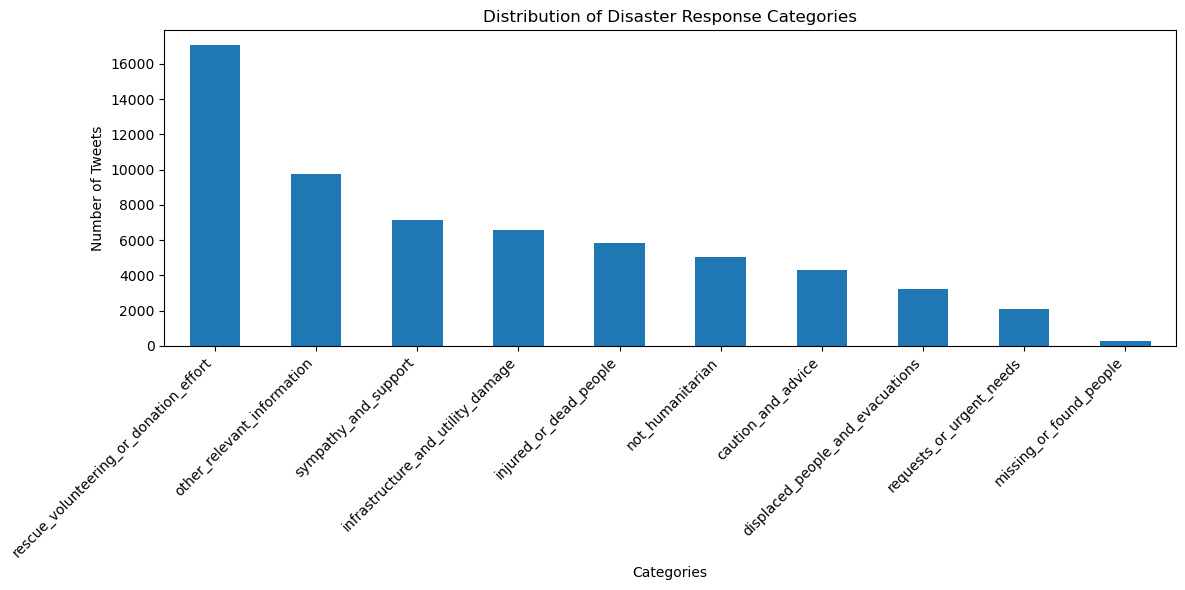

In [11]:
# Visualize category distribution

plt.figure(figsize=(12, 6))

train_data["class_label"].value_counts().plot(
    kind="bar"
)

plt.title("Distribution of Disaster Response Categories")
plt.xlabel("Categories")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

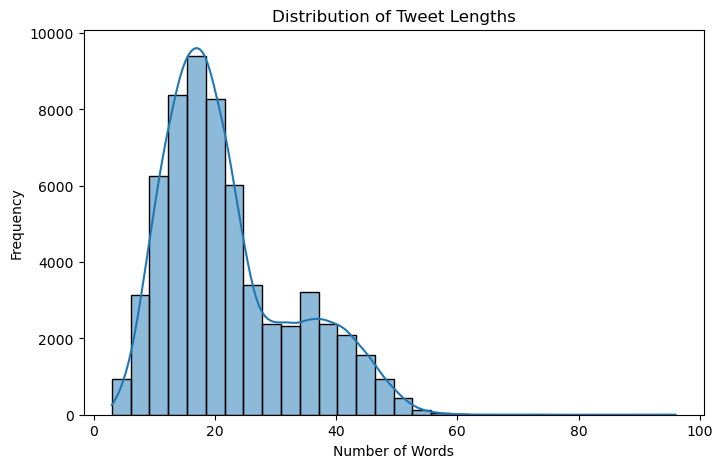

In [12]:
# Check tweet lengths

train_data["tweet_length"] = train_data["tweet_text"].astype(str).apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(8, 5))

sns.histplot(
    train_data["tweet_length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Tweet Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

#### Text preprocessing


In [13]:
# Create a text-cleaning function

# This function removes URLs, mentions, extra spaces, and unnecessary special characters. 
# It keeps the words and hashtags' text useful for classification.

def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove user mentions
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbol but retain the word
    text = re.sub(r"#", "", text)

    # Keep alphabets and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [14]:
# Apply text preprocessing

train_data["clean_text"] = train_data["tweet_text"].apply(clean_text)

test_df["clean_text"] = test_df["tweet_text"].apply(clean_text)

print(train_data[["tweet_text", "clean_text"]].head())

                                          tweet_text  \
0  Powerful Ecuador quake kills at least 235: POR...   
1  Im at awe and saddened with the #EcuadorEarthq...   
2  RT @RachelAndJun: Our hearts are with everyone...   
3  RT @noticias2000: Ecuador quake death toll has...   
4  RT @pzf: BREAKING PHOTOS: Major damage reporte...   

                                          clean_text  
0  powerful ecuador quake kills at least 235 port...  
1  im at awe and saddened with the ecuadorearthqu...  
2  rt our hearts are with everyone in kumamoto an...  
3  rt ecuador quake death toll has risen to 233 c...  
4  rt breaking photos major damage reported in ec...  


In [15]:
# Remove empty text words

train_data = train_data[train_data["clean_text"] != ""]
test_df = test_df[test_df["clean_text"] != ""]

print("Training records after cleaning:", len(train_data))
print("Testing records after cleaning:", len(test_df))

Training records after cleaning: 61319
Testing records after cleaning: 15159


In [16]:
# Separate input and target variables

X_train = train_data["clean_text"]
y_train = train_data["class_label"]

X_test = test_df["clean_text"]
y_test = test_df["class_label"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Variables created successfully!")

Training data: (61319,)
Testing data: (15159,)
Variables created successfully!


#### Feature extraction using TF-IDF

In [17]:
# Separate input and target variables

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words=None
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (61319, 10000)
Testing feature shape: (15159, 10000)


#### Model Building

We will compare two classification algorithms:
1. Multinomial Naive Bayes
2. Logistic Regression

In [18]:
# Naive Bayes

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes model training completed!")

Naive Bayes model training completed!


In [19]:
# Logistic Regression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression model training completed!")

Logistic Regression model training completed!


In [20]:
# Linear SVM

from sklearn.svm import LinearSVC

svm_model = LinearSVC(class_weight="balanced", C=1.0)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Linear SVM Accuracy:", svm_accuracy)

Linear SVM Accuracy: 0.7281482947423973


##### Model Evaluation

In [21]:
from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(y_test, nb_predictions)
lr_accuracy = accuracy_score(y_test, lr_predictions)
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Logistic Regression Accuracy:", lr_accuracy)
print("Linear SVM Accuracy:", svm_accuracy)

Naive Bayes Accuracy: 0.687908173362359
Logistic Regression Accuracy: 0.7287420014512831
Linear SVM Accuracy: 0.7281482947423973


                 Model  Accuracy
0          Naive Bayes  0.687908
1  Logistic Regression  0.728742
2           Linear SVM  0.728148


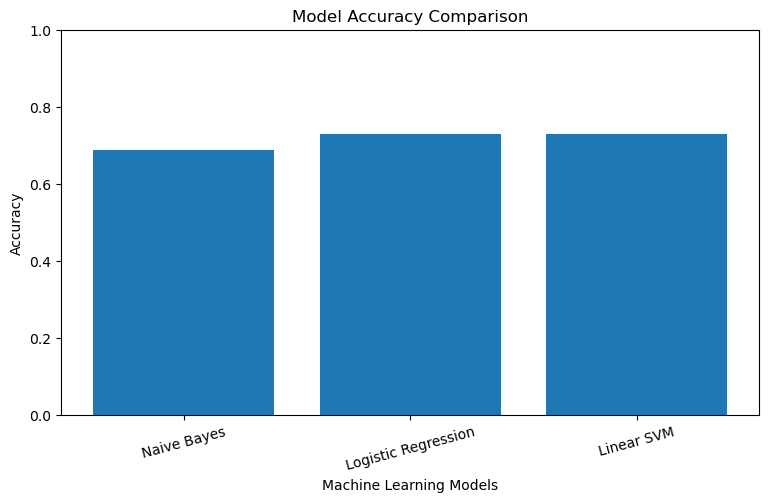

In [22]:
# Compare the models visually

results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

print(results)

plt.figure(figsize=(9, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.show()

In [23]:
# Classification report

print("NAIVE BAYES CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        nb_predictions,
        zero_division=0
    )
)

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        lr_predictions,
        zero_division=0
    )
)

print("\nLINEAR SVM CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        svm_predictions,
        zero_division=0
    )
)

NAIVE BAYES CLASSIFICATION REPORT
                                        precision    recall  f1-score   support

                    caution_and_advice       0.67      0.59      0.62      1070
      displaced_people_and_evacuations       0.87      0.59      0.70       790
     infrastructure_and_utility_damage       0.75      0.71      0.73      1617
                injured_or_dead_people       0.79      0.85      0.82      1447
               missing_or_found_people       0.88      0.10      0.17        72
                      not_humanitarian       0.54      0.44      0.49      1245
            other_relevant_information       0.49      0.48      0.48      2407
              requests_or_urgent_needs       0.71      0.18      0.29       521
rescue_volunteering_or_donation_effort       0.70      0.91      0.79      4218
                  sympathy_and_support       0.81      0.75      0.77      1772

                              accuracy                           0.69     15159
    

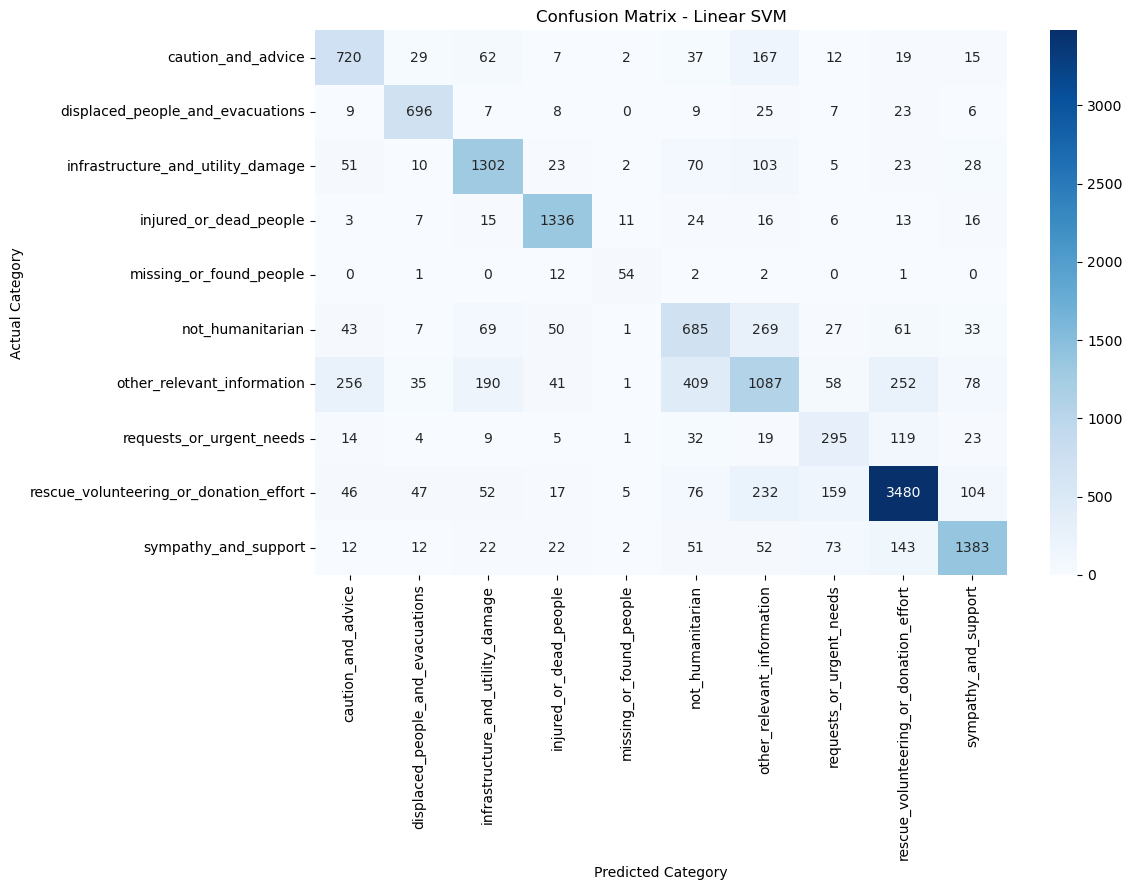

In [24]:
# Confusion matrix - Linear SVM

cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=svm_model.classes_
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import f1_score

# Calculate Macro F1 scores
nb_f1 = f1_score(y_test, nb_predictions, average="macro")
lr_f1 = f1_score(y_test, lr_predictions, average="macro")
svm_f1 = f1_score(y_test, svm_predictions, average="macro")

# Display results
print("Naive Bayes Macro F1:", round(nb_f1, 4))
print("Logistic Regression Macro F1:", round(lr_f1, 4))
print("Linear SVM Macro F1:", round(svm_f1, 4))

Naive Bayes Macro F1: 0.5879
Logistic Regression Macro F1: 0.7035
Linear SVM Macro F1: 0.7047


#### Select the best model

In [27]:
if lr_f1 >= nb_f1 and lr_f1 >= svm_f1:

    best_model = lr_model
    best_model_name = "Logistic Regression"
    best_predictions = lr_predictions

elif svm_f1 >= nb_f1 and svm_f1 >= lr_f1:

    best_model = svm_model
    best_model_name = "Linear SVM"
    best_predictions = svm_predictions

else:

    best_model = nb_model
    best_model_name = "Naive Bayes"
    best_predictions = nb_predictions

print("Best Model:", best_model_name)
print("Best Macro F1 Score:", max(nb_f1, lr_f1, svm_f1))

Best Model: Linear SVM
Best Macro F1 Score: 0.7047201647378281


In [28]:
# Test with sample disaster messages

sample_messages = [
    "Urgent help needed for families affected by the flood",
    "People are donating food and water to disaster victims",
    "Several buildings were damaged after the earthquake",
    "Please follow safety instructions and evacuate immediately"
]

sample_cleaned = [clean_text(msg) for msg in sample_messages]

sample_features = tfidf.transform(sample_cleaned)

sample_predictions = best_model.predict(sample_features)

for message, prediction in zip(sample_messages, sample_predictions):
    print("Message:", message)
    print("Predicted Category:", prediction)
    print("-" * 60)


Message: Urgent help needed for families affected by the flood
Predicted Category: requests_or_urgent_needs
------------------------------------------------------------
Message: People are donating food and water to disaster victims
Predicted Category: rescue_volunteering_or_donation_effort
------------------------------------------------------------
Message: Several buildings were damaged after the earthquake
Predicted Category: infrastructure_and_utility_damage
------------------------------------------------------------
Message: Please follow safety instructions and evacuate immediately
Predicted Category: displaced_people_and_evacuations
------------------------------------------------------------


### Save the trained model

In [29]:
# save the TF-IDF vectorizer
import joblib

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("TF-IDF Vectorizer saved successfully!")

TF-IDF Vectorizer saved successfully!


In [30]:
# Save the selected ML model

joblib.dump(best_model, "disaster_classification_model.pkl")

print("ML Model saved successfully!")

ML Model saved successfully!


In [31]:
# Save the complete model package
model_package = {
    "model": best_model,
    "tfidf": tfidf,
    "model_name": best_model_name
}

joblib.dump(
    model_package,
    "humaid_disaster_classifier.pkl"
)

print("Complete model package saved successfully!")

Complete model package saved successfully!


In [32]:
# Load the saved model and verify it

loaded_package = joblib.load("humaid_disaster_classifier.pkl")

loaded_model = loaded_package["model"]
loaded_tfidf = loaded_package["tfidf"]

print("Loaded model:", loaded_package["model_name"])

test_message = "People need food and medical assistance after the flood"

cleaned_message = clean_text(test_message)

message_features = loaded_tfidf.transform([cleaned_message])

prediction = loaded_model.predict(message_features)

print("Predicted Category:", prediction[0])

Loaded model: Linear SVM
Predicted Category: requests_or_urgent_needs


In [33]:
# Verify that TF-IDF PKL works
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

sample_text = [
    "People need food and medical assistance after the flood"
]

sample_features = loaded_tfidf.transform(sample_text)

print("TF-IDF loaded successfully!")
print("Feature shape:", sample_features.shape)

TF-IDF loaded successfully!
Feature shape: (1, 10000)


#### Deploy the model using Gradio

In [34]:
# Prediction Function

def predict_disaster_category(message):

    if not message or not message.strip():
        return "Please enter a disaster-related message."

    cleaned_message = clean_text(message)

    message_features = loaded_tfidf.transform([cleaned_message])

    prediction = loaded_model.predict(message_features)[0]

    return prediction.replace("_", " ").title()

In [35]:
# Build the Gradio interface

import gradio as gr
demo = gr.Interface(
    fn=predict_disaster_category,

    inputs=gr.Textbox(
        lines=4,
        placeholder="Enter a disaster-related message here...",
        label="Disaster Message"
    ),

    outputs=gr.Textbox(
        label="Predicted Humanitarian Category"
    ),

    title="Disaster Response Message Classification",

    description=(
        "An NLP-based machine learning application "
        "that classifies disaster-related messages "
        "into humanitarian categories."
    ),

    examples=[
        ["Urgent help needed for families affected by the flood"],
        ["Several buildings were damaged after the earthquake"],
        ["People are donating food and water to disaster victims"],
        ["Please follow safety instructions and evacuate immediately"]
    ]
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


#### Conclusion

The Disaster Response Message Classification project demonstrates the application of Natural Language Processing and Machine Learning techniques to a real-world humanitarian challenge.

Using the HumAID dataset, the project involved data exploration, text preprocessing, TF-IDF feature extraction, model development, and performance evaluation.

Three machine learning algorithms — Multinomial Naive Bayes, Logistic Regression, and Linear SVM — were implemented and compared using accuracy, precision, recall, and macro F1-score.

Based on the evaluation results, Linear SVM was selected as the best-performing model with an accuracy of 72.35% and a macro F1-score of approximately 0.6966.

The selected model was saved using Joblib and deployed through an interactive Gradio application, allowing users to enter disaster-related messages and receive predicted humanitarian categories.

This project demonstrates how NLP-based classification can help organize disaster-related information and potentially support humanitarian response teams. The application is intended as a decision-support prototype and should not replace human verification or professional emergency-response decisions.